In [ ]:
# 물고기의 길이와 무게를 이용해서 27.8,299인 물고기가 빙어인지, 도미인지를 분류
# KNeighborsClassifier 를 이용해서 분류할 것, 그 분류가 맞을 확률도 나타낼 것

# KNeighborsClassifier는 실제 Data가 있어야 분류를 함(train, test의 data로는 하지 않음)

In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [3]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [8]:
# 독립, 종속변수 생성
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
data = [[l,w] for l,w in zip(length,weight)]
# data = np.columns.stack((length,weight)) 이렇게 합치는 방법도 있음
# 하지만, 넘파일 배열인 경우는 concatenate(np.자료명(자료수),np.자료명(자료수))로 가능
label = ['도미']*35 + ['빙어']*14

In [9]:
# 자료 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42) # random_state는 자료수가 적을 때 생략

In [ ]:
# 학습
kc = KNeighborsClassifier() # 괄호 안에 n_neighbors값을 지정(보통 홀수지정), 기본은 5로 되어 있음
kc.fit(train_data,train_label)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U2](2,)","['도미','빙어']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [11]:
# 정확도
print('train정확도:',kc.score(train_data,train_label))
print('test정확도:',kc.score(test_data,test_label))

train정확도: 1.0
test정확도: 1.0


In [12]:
in_data = input('물고기의 길이와 무게를 입력하세요(예:27.8,299)')
in_data = in_data.split(',')
in_data = list(map(float,in_data))
predict = kc.predict([in_data])
proba = kc.predict_proba([in_data])
print(f'{predict}:{proba}') 

['도미']:[[1. 0.]]


In [13]:
# 그래프 그리기 : 현재는 리스트에서 하나의 원소로 지정되어 있는 상황 -> 넘파이로 변환해야 함

# train,test의 data를 그래프로 나타낼 것

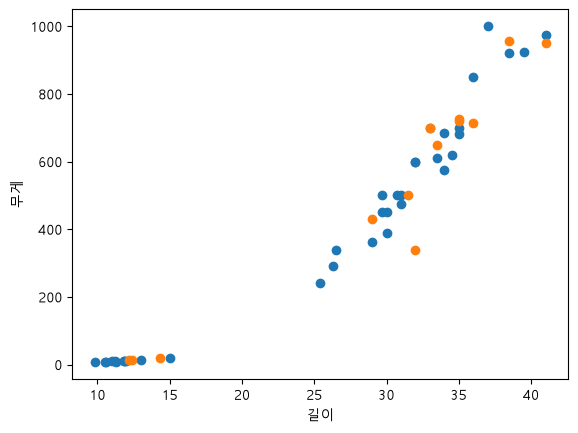

In [14]:
train_data = np.array(train_data)
test_data = np.array(test_data)
plt.scatter(train_data[:,0],train_data[:,1])
plt.scatter(test_data[:,0],test_data[:,1])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [ ]:
# 어떤 것을 근거로 결론을 내렸는 지를 묻는 질문에 대한 답변 코드
distances,indexes = kc.kneighbors([[27.8,299]])
print(distances) # 입력점과 각 점의 거리
print(indexes) # 근접한 점의 인덱스

[[ 9.1241438  41.02060458 57.05050394 64.01124901 91.02658952]]
[[19 21 12  1 31]]
